# Stronghold Demobilization: Size, Partisanship, and the Counterfactual

Part 2 found that Democratic strongholds lost votes through turnout. This notebook sizes that, asks who the stay-homes were, and runs the counterfactual that matters: if 2020 voters who stayed home in 2024 had voted as they did in 2020, what changes?

The counterfactual needs the partisan lean of the stay-homes, which county returns cannot give. Two individual-level sources can:

- **CES 2024 cross-section** (60,000; 34,666 matched to a voter file with a recalled 2020 vote). Large, retains disengaged respondents, but 2020 vote is recalled.
- **CES 2020–2024 panel** (6,175). 2020 vote reported in 2020, but the retained panel is engaged and under-represents exactly the people who stay home.

Both have TargetSmart-validated 2024 turnout. Results are reported unweighted and under each CES weight, because the answer turns out to depend on it.

**Inputs:** `data/processed/county_decomposition.csv`, `data/raw/mit_election_lab/county_returns.csv`, `data/raw/ces/CCES24_Common_OUTPUT_vv_topost_final.csv`, `data/raw/ces_panel/ces_panel_wide.csv`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

RAW_DIR = Path('../data/raw'); PROC_DIR = Path('../data/processed')
FIGURES_DIR = Path('../outputs/figures'); TABLES_DIR = Path('../outputs/tables')

def wmean(x, w):
    m = x.notna() & w.notna()
    return np.average(x[m], weights=w[m]) if m.any() else np.nan

SWING = ['PENNSYLVANIA', 'MICHIGAN', 'WISCONSIN', 'GEORGIA', 'ARIZONA', 'NEVADA', 'NORTH CAROLINA']
SWING_FIPS = {42: 'PENNSYLVANIA', 26: 'MICHIGAN', 55: 'WISCONSIN', 13: 'GEORGIA', 4: 'ARIZONA', 32: 'NEVADA', 37: 'NORTH CAROLINA'}

## 1. Size: Democratic vote change by county partisanship

In [2]:
c = pd.read_csv(PROC_DIR / 'county_decomposition.csv')
c['bin'] = pd.cut(c['dem_share_2020'], [0, .35, .45, .55, .65, 1.01],
                  labels=['<35% (R strongholds)', '35-45%', '45-55% (competitive)', '55-65% (lean D)', '65%+ (D strongholds)'])
rows = []
for b, g in c.groupby('bin'):
    rows.append({'county_2020_dem_share': b, 'counties': len(g), 'share_of_2020_votes': g['total_votes_2020'].sum() / c['total_votes_2020'].sum(),
                 'share_of_2020_dem_votes': g['dem_votes_2020'].sum() / c['dem_votes_2020'].sum(),
                 'delta_dem_M': g['delta_dem'].sum() / 1e6, 'turnout_component_M': g['turnout_component'].sum() / 1e6,
                 'share_component_M': g['share_component'].sum() / 1e6,
                 'turnout_change_pct': (g['total_votes_2024'].sum() / g['total_votes_2020'].sum() - 1) * 100,
                 'dem_share_change_pp': (g['dem_votes_2024'].sum() / g['total_votes_2024'].sum() - g['dem_votes_2020'].sum() / g['total_votes_2020'].sum()) * 100})
by_bin = pd.DataFrame(rows).set_index('county_2020_dem_share')
print(by_bin.round(3).to_string())
s = c[c['dem_share_2020'] >= .65]
print(f'\nD strongholds (65%+): {len(s)} counties, {s["total_votes_2020"].sum() / c["total_votes_2020"].sum():.1%} of 2020 votes, {s["dem_votes_2020"].sum() / c["dem_votes_2020"].sum():.1%} of 2020 Dem votes')
print(f'  Dem votes {s["dem_votes_2020"].sum() / 1e6:.2f}M -> {s["dem_votes_2024"].sum() / 1e6:.2f}M ({s["dem_votes_2024"].sum() / s["dem_votes_2020"].sum() - 1:+.1%})')
print(f'  non-Dem votes {(s["total_votes_2020"] - s["dem_votes_2020"]).sum() / 1e6:.2f}M -> {(s["total_votes_2024"] - s["dem_votes_2024"]).sum() / 1e6:.2f}M')
print(f'  share of national Dem vote loss: {s["delta_dem"].sum() / c["delta_dem"].sum():.0%}   share of national turnout component: {s["turnout_component"].sum() / c["turnout_component"].sum():.0%}')
print(f'  in 7 swing states: {s[s["state"].isin(SWING)]["delta_dem"].sum() / 1e6:+.2f}M   CA+NY+IL: {s[s["state"].isin(["CALIFORNIA", "NEW YORK", "ILLINOIS"])]["delta_dem"].sum() / 1e6:+.2f}M')
top = s.nsmallest(10, 'delta_dem')[['state', 'county_fips', 'dem_share_2020', 'dem_votes_2020', 'dem_votes_2024', 'delta_dem', 'turnout_component', 'share_component']]
print('\nLargest stronghold Dem vote losses:'); print(top.round(0).astype({'delta_dem': int, 'turnout_component': int, 'share_component': int}).to_string(index=False))

                       counties  share_of_2020_votes  share_of_2020_dem_votes  delta_dem_M  turnout_component_M  share_component_M  turnout_change_pct  dem_share_change_pp
county_2020_dem_share                                                                                                                                                      
<35% (R strongholds)       1903                0.187                    0.096       -0.157                0.167             -0.324               2.135               -1.069
35-45%                      539                0.156                    0.122       -0.288                0.108             -0.396               1.171               -1.618
45-55% (competitive)        322                0.226                    0.224       -1.198               -0.270             -0.929              -1.404               -2.677
55-65% (lean D)             197                0.219                    0.254       -1.678               -0.802             -0.876          

## 2. Who stayed home: partisanship of 2020 voters who did not vote in 2024

Validated non-voting in 2024 by 2020 vote, from both sources. `TS_g2024` is TargetSmart's 2024 general-election record (1–6 voted by method, 7 did not vote, missing = not matched).

In [3]:
# Cross-section
raw = pd.read_csv(RAW_DIR / 'ces' / 'CCES24_Common_OUTPUT_vv_topost_final.csv',
                  usecols=['caseid', 'inputstate', 'TS_g2024', 'TS_voterstatus', 'vvweight', 'vvweight_post', 'commonweight', 'presvote20post', 'CC24_410', 'birthyr', 'educ', 'race', 'hispanic'], low_memory=False)
raw['matched'] = raw['TS_voterstatus'].notna() | raw['TS_g2024'].notna()
raw['stay'] = np.where(raw['TS_g2024'].notna() & (raw['TS_g2024'] != 7), 0.0, np.where(raw['matched'], 1.0, np.nan))
raw['v20'] = raw['presvote20post'].map({1: 'Biden', 2: 'Trump', 3: 'other', 4: 'other', 5: 'other', 6: 'did not vote'})
raw['v24'] = np.select([raw['CC24_410'] == 1, raw['CC24_410'] == 2, raw['CC24_410'].between(3, 7)], ['Harris', 'Trump', 'third party'], None)
xs = raw[raw['matched'] & raw['v20'].isin(['Biden', 'Trump'])].copy()
xs['wt'] = xs['vvweight_post'].fillna(xs['vvweight']).fillna(xs['commonweight'])

# Panel
wp = pd.read_csv(RAW_DIR / 'ces_panel' / 'ces_panel_wide.csv', low_memory=False)
pn = wp[(wp['voted_validated_2020'] == 1) & wp['voted_validated_2024'].notna() & wp['presvote_post_party_2020'].isin(['D', 'R'])].copy()
pn['wt'] = pn['commonpostweight_24'].fillna(pn['commonweight_24'])
pn['stay'] = (pn['voted_validated_2024'] == 0).astype(float)
pn['v20'] = pn['presvote_post_party_2020'].map({'D': 'Biden', 'R': 'Trump'})
pn['v24'] = pn['presvote_post_party_2024'].map({'D': 'Harris', 'R': 'Trump', 'other': 'third party'})

xs['one'] = 1.0; pn['one'] = 1.0
rows = []
for name, df, weights in [('cross-section', xs, ['one', 'commonweight', 'vvweight']), ('panel', pn, ['one', 'commonweight_24'])]:
    for w in weights:
        d = df[df['v20'] == 'Biden']; r = df[df['v20'] == 'Trump']; sh = df[df['stay'] == 1]
        rows.append({'source': name, 'weight': w, 'N': len(df), 'N_stay_home': len(sh),
                     'stay_Biden': wmean(d['stay'], d[w]), 'stay_Trump': wmean(r['stay'], r[w]),
                     'stay_homes_pct_Biden': wmean((sh['v20'] == 'Biden').astype(float), sh[w]),
                     'recalled_D_over_R': d[w].sum() / r[w].sum()})
who = pd.DataFrame(rows).set_index(['source', 'weight'])
print(who.round(3).to_string())
print('\nActual 2020 Biden/Trump ratio: 1.09. The cross-section over-recalls Biden votes unweighted (1.42); the CES weights,')
print('which rake on 2020 vote, correct this (1.08-1.12). No further recall adjustment is needed or applied.')
print('\nUnweighted, Biden and Trump 2020 voters stayed home at the same rate. The weighted differential comes from the weights.')

xs['age'] = 2024 - xs['birthyr']
xs['grp'] = np.select([xs['hispanic'] == 1, xs['race'] == 2, xs['age'] < 35, xs['educ'] <= 3],
                      ['Hispanic', 'Black', 'under 35 (other)', 'no degree (other)'], 'other')
rows = []
for g, x in xs.groupby('grp'):
    d = x[x['v20'] == 'Biden']; r = x[x['v20'] == 'Trump']
    rows.append({'group': g, 'N_Biden': len(d), 'stay_Biden_unwtd': d['stay'].mean(), 'N_Trump': len(r), 'stay_Trump_unwtd': r['stay'].mean(),
                 'mean_vvweight_Biden': d['vvweight'].mean(), 'mean_vvweight_Trump': r['vvweight'].mean(),
                 'share_of_Biden_voters': len(d) / (xs['v20'] == 'Biden').sum()})
by_grp = pd.DataFrame(rows).set_index('group')
print('\nStay-home rate by demographic group and 2020 vote (unweighted):')
print(by_grp.round(3).to_string())
print('\nWithin every group, Trump 2020 voters stayed home at an equal or higher rate. Biden voters are concentrated in the')
print('high-stay-home groups (Black, Hispanic, under 35), and the weights up-weight those groups. The aggregate weighted')
print('differential is composition of the coalitions, not a greater propensity of Biden voters to stay home.')

                                   N  N_stay_home  stay_Biden  stay_Trump  stay_homes_pct_Biden  recalled_D_over_R
source        weight                                                                                              
cross-section one              34666         1961       0.057       0.056                 0.589              1.421
              commonweight     34666         1961       0.044       0.038                 0.556              1.076
              vvweight         34666         1961       0.080       0.059                 0.605              1.119
panel         one               3982          136       0.032       0.037                 0.529              1.278
              commonweight_24   3982          136       0.024       0.046                 0.355              1.038

Actual 2020 Biden/Trump ratio: 1.09. The cross-section over-recalls Biden votes unweighted (1.42); the CES weights,
which rake on 2020 vote, correct this (1.08-1.12). No further recall adjustmen

## 3. Stay home or flip? Outcomes for 2020 voters who left their 2020 column

In [4]:
def outcomes(df, p, flip):
    b = df[df['v20'] == p].copy()
    b['o'] = np.where(b['stay'] == 1, 'stayed home', b['v24'].fillna('voted, no answer'))
    k = b[b['o'] != 'voted, no answer']
    same = 'Harris' if p == 'Biden' else 'Trump'
    left = k[k['o'] != same]
    return {'N_known': len(k), **{o: wmean((k['o'] == o).astype(float), k['wt']) for o in [same, flip, 'third party', 'stayed home']},
            'N_left': len(left),
            'of_leavers_stayed_home': wmean((left['o'] == 'stayed home').astype(float), left['wt']),
            'of_leavers_flipped': wmean((left['o'] == flip).astype(float), left['wt']),
            'of_leavers_third': wmean((left['o'] == 'third party').astype(float), left['wt'])}
rows = []
for name, df in [('cross-section', xs), ('panel', pn)]:
    for p, flip in [('Biden', 'Trump'), ('Trump', 'Harris')]:
        rows.append({'source': name, '2020 vote': p, **outcomes(df, p, flip)})
flipstay = pd.DataFrame(rows).set_index(['source', '2020 vote'])
print(flipstay.round(3).T.to_string())

source                 cross-section                panel          
2020 vote                      Biden      Trump     Biden     Trump
N_known                    18182.000  13517.000  1391.000  1345.000
Harris                         0.844      0.015     0.957     0.029
Trump                          0.047      0.918     0.014     0.920
third party                    0.009      0.004     0.006     0.014
stayed home                    0.100      0.063     0.024     0.037
N_left                      1709.000   1277.000   112.000   115.000
of_leavers_stayed_home         0.645      0.761     0.553     0.457
of_leavers_flipped             0.300      0.188     0.314     0.363
of_leavers_third               0.056      0.051     0.133     0.180


## 4. Counterfactual: 2020 voters who stayed home in 2024 vote as they did in 2020

Stay-home rates by 2020 vote from the cross-section, by state, applied to actual 2020 state vote totals. Net margin effect = (Biden 2020 votes × Biden stay rate) − (Trump 2020 votes × Trump stay rate). Compared to the actual 2024 margin.

This is the correct counterfactual for "what if the stay-homes had voted." It is not the one in Part 2's county analysis, which assumed stay-homes voted like the 2024 electorate and therefore found no effect.

In [5]:
ret = pd.read_csv(RAW_DIR / 'mit_election_lab' / 'county_returns.csv')
s20 = ret[ret['year'] == 2020].groupby('state')[['dem_votes', 'rep_votes']].sum()
s24 = ret[ret['year'] == 2024].groupby('state')[['dem_votes', 'rep_votes']].sum()
rows = []
for f, st in list(SWING_FIPS.items()) + [(None, 'NATIONAL')]:
    x = xs if f is None else xs[xs['inputstate'] == f]; d = x[x['v20'] == 'Biden']; r = x[x['v20'] == 'Trump']
    marg = (s24['dem_votes'].sum() - s24['rep_votes'].sum()) if f is None else s24.loc[st, 'dem_votes'] - s24.loc[st, 'rep_votes']
    D20 = s20['dem_votes'].sum() if f is None else s20.loc[st, 'dem_votes']; R20 = s20['rep_votes'].sum() if f is None else s20.loc[st, 'rep_votes']
    row = {'state': st, 'margin_2024': marg, 'n_Biden': len(d), 'n_Trump': len(r), 'stay_homes_Biden': int(d['stay'].sum()), 'stay_homes_Trump': int(r['stay'].sum())}
    for w in ['one', 'commonweight', 'vvweight']:
        sd, sr = wmean(d['stay'], d[w]), wmean(r['stay'], r[w])
        row[f'net_{w}'] = D20 * sd - R20 * sr; row[f'flips_{w}'] = marg + D20 * sd - R20 * sr > 0
    pd_, pr_ = d['stay'].mean(), r['stay'].mean()
    se = np.sqrt((D20 * np.sqrt(pd_ * (1 - pd_) / len(d))) ** 2 + (R20 * np.sqrt(pr_ * (1 - pr_) / len(r))) ** 2)
    row['net_one_ci_lo'] = row['net_one'] - 1.96 * se; row['net_one_ci_hi'] = row['net_one'] + 1.96 * se
    rows.append(row)
cf = pd.DataFrame(rows).set_index('state')
show = cf[['margin_2024', 'n_Biden', 'n_Trump', 'net_one', 'net_one_ci_lo', 'net_one_ci_hi', 'net_commonweight', 'net_vvweight', 'flips_one', 'flips_commonweight', 'flips_vvweight']]
print('Net margin change (votes) if 2020 stay-homes had voted as in 2020, by weighting of the stay-home rates:')
print(show.round(0).to_string())
print()
print('No state flips unweighted or with commonweight. Michigan flips only under vvweight, on 41 Biden and 24 Trump')
print('stay-homes; the unweighted 95% CI on its net effect spans zero. Nationally the net is +0.4M to +2.2M against a')
print('2.29M deficit: the popular vote does not flip under any weighting.')

Net margin change (votes) if 2020 stay-homes had voted as in 2020, by weighting of the stay-home rates:
                margin_2024  n_Biden  n_Trump   net_one  net_one_ci_lo  net_one_ci_hi  net_commonweight  net_vvweight  flips_one  flips_commonweight  flips_vvweight
state                                                                                                                                                               
PENNSYLVANIA        -120266     1043      855  -22361.0       -76455.0        31734.0          -17457.0      -17276.0      False               False           False
MICHIGAN             -80103      736      468   20313.0       -50135.0        90762.0           51069.0      182835.0      False               False            True
WISCONSIN            -29397      457      296  -11576.0       -52438.0        29287.0            6506.0      -10013.0      False               False           False
GEORGIA             -115100      656      471   -5920.0       -76639.0 

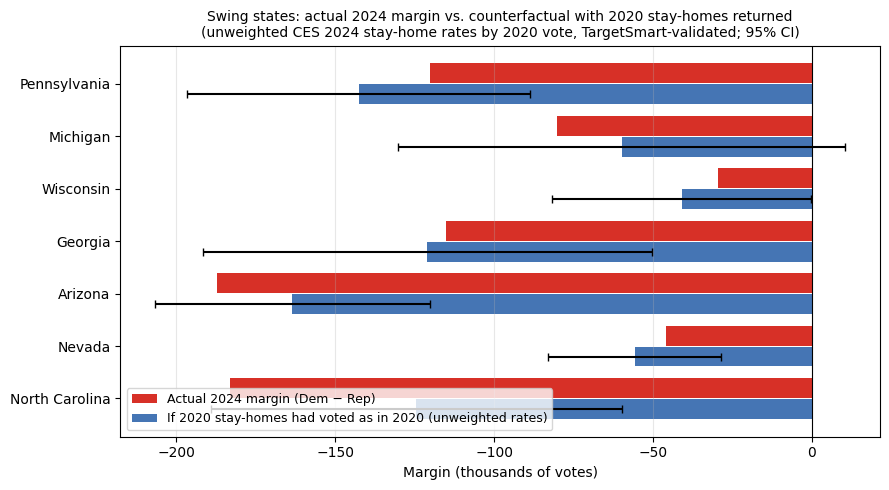

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
st = cf.drop(index='NATIONAL')
y = np.arange(len(st))[::-1]
ax.barh(y + 0.2, st['margin_2024'] / 1e3, height=0.38, color='#d73027', label='Actual 2024 margin (Dem − Rep)')
cfm = (st['margin_2024'] + st['net_one']) / 1e3
ax.barh(y - 0.2, cfm, height=0.38, color='#4575b4', label='If 2020 stay-homes had voted as in 2020 (unweighted rates)')
ax.errorbar(cfm, y - 0.2, xerr=(st['net_one_ci_hi'] - st['net_one']) / 1e3, fmt='none', ecolor='black', capsize=3)
ax.axvline(0, color='black', lw=0.8)
ax.set_yticks(y); ax.set_yticklabels([s.title() for s in st.index])
ax.set_xlabel('Margin (thousands of votes)')
ax.set_title('Swing states: actual 2024 margin vs. counterfactual with 2020 stay-homes returned\n(unweighted CES 2024 stay-home rates by 2020 vote, TargetSmart-validated; 95% CI)', fontsize=10)
ax.legend(fontsize=9, loc='lower left'); ax.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.savefig(FIGURES_DIR / 'stayhome_counterfactual.png', dpi=150, bbox_inches='tight'); plt.show()

## 5. Save

In [7]:
by_bin.to_csv(TABLES_DIR / 'stayhome_by_county_bin.csv'); who.to_csv(TABLES_DIR / 'stayhome_partisanship.csv')
flipstay.to_csv(TABLES_DIR / 'stayhome_vs_flip.csv'); cf.to_csv(TABLES_DIR / 'stayhome_counterfactual.csv'); by_grp.to_csv(TABLES_DIR / 'stayhome_by_group.csv')
print('Saved: outputs/tables/stayhome_by_county_bin.csv, stayhome_partisanship.csv, stayhome_vs_flip.csv, stayhome_counterfactual.csv; outputs/figures/stayhome_counterfactual.png')

Saved: outputs/tables/stayhome_by_county_bin.csv, stayhome_partisanship.csv, stayhome_vs_flip.csv, stayhome_counterfactual.csv; outputs/figures/stayhome_counterfactual.png


## Limitations

- **The partisan differential is weight-dependent, and unweighted it is zero.** Biden and Trump 2020 voters stayed home at 5.7% and 5.6% unweighted. The differential appears only under weights that up-weight low-turnout demographic groups where Biden voters are concentrated. Within those groups, Trump voters stayed home as much or more. The aggregate weighted figure describes the coalitions' composition, not a partisan propensity to abstain.
- **State cells are small.** Michigan's vvweight flip rests on 41 stay-homes; the unweighted CI on its net effect is [−50k, +91k] against an 80k deficit.
- **Recall.** The cross-section over-recalls Biden votes unweighted; the CES weights correct this. No separate adjustment is applied.
- **Everything else is held fixed.** Roughly 11M 2020 voters dropped out and 8M new voters entered. Returning the drop-outs does not remove the new voters.
- **The county-level stronghold turnout collapse is real; this notebook shows it was not 2020 Democratic voters defecting to non-voting at a higher rate than Republicans.** What remains: the 2020 surge of marginal and first-time voters not repeating, the Democratic coalition's higher baseline non-voting demographics, and out-migration from California, New York, and Illinois between 2020 and 2024. None of these is a differential response by 2020 Democratic voters.